<a href="https://colab.research.google.com/github/gs0232/IPPR_CT_Reconstruction/blob/main/Baselines/03_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 – Evaluation of all methods (Sophia)

Compares the reconstructions of **NeRF**, **3DGS** (and U-Net, once available) with the
ground truth and with the **FBP baseline** (98 views) on exactly the same slices.

**Which files are used**
| what | where | format |
|---|---|---|
| Ground truth | `baseline_results/gt_fullview_npy/series_XXXX_sliceYY.npy` | float, 888×888, full-view FBP (984 views), every 4th slice |
| NeRF / 3DGS / U-Net | `outputs/<method>/series_XXXX_sliceYY_v098.png` (only files directly in the folder, not `previews/`) | 8-bit PNG, 888×888 |
| FBP baseline | computed here from the original sinograms in `SinoCT_files.zip` with the same 98 angles | |

Souram's `full_output` PNGs are **not** used (8-bit, each image stretched separately).

**Steps**
1. Inventory: which output files exist, what size/format they have.
2. Match every output PNG to its ground-truth slice (by series and slice number).
3. Bring all images onto the same footing (same size, same intensity scale).
4. Compute PSNR / SSIM / RMSE with `metrics.py` (whole image + head only).
5. Summary table (mean ± SD per method), comparison figure, CSV for the report.

**Fairness rule:** the outputs are 8-bit PNGs. So the FBP baseline is passed through
*exactly the same PNG treatment* (min-max → 8 bit) before it is scored. Otherwise FBP would
have an unfair advantage from being stored as float.

## 0. Setup

In [17]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/IPPR_CT_Reconstruction"):
        !git clone -q https://github.com/gs0232/IPPR_CT_Reconstruction.git /content/IPPR_CT_Reconstruction
    sys.path.insert(0, "/content/IPPR_CT_Reconstruction/Baselines")
else:
    sys.path.insert(0, ".")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import re, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.transform import iradon, resize

import metrics
metrics._self_test()

metrics.py self-test passed: {'psnr': 26.054, 'ssim': 0.301, 'rmse': 0.05, 'psnr_head': 26.124, 'ssim_head': 0.403, 'rmse_head': 0.049}


## 1. Configuration

In [19]:
DATA_ROOT   = Path("/content/drive/MyDrive/MGST_5_IPPR_CT_Reconstruction")   # <- adjust if needed
OUTPUT_ROOT = DATA_ROOT / "outputs"                 # outputs/nerf, outputs/3dgs, outputs/unet
GT_ROOT     = DATA_ROOT / "baseline_results" / "gt_fullview_npy"   # series_XXXX_sliceYY.npy (every 4th slice)
SINO_ZIP    = DATA_ROOT / "SinoCT_files.zip"        # original sinograms (for the FBP baseline)
SINO_DIR    = Path("/content/sinograms")            # unzipped to Colab's local disk
EVAL_DIR    = DATA_ROOT / "evaluation_results"
EVAL_DIR.mkdir(exist_ok=True)

METHODS     = ["nerf", "3dgs", "unet"]              # folders inside outputs/ (missing ones are skipped)
N_VIEWS     = 98                                    # sparse level the methods started from
EVAL_SERIES = [f"series_{i}" for i in range(1030, 1040)]   # agreed validation series 1030–1039
IMG_SIZE    = 888
N_ANGLES    = 984
THETA_FULL  = np.linspace(0, 360, N_ANGLES, endpoint=False)

## 2. Inventory – what did the others deliver?
Run this first and look at the output: number of files, file names, image size and mode.

In [20]:
def find_id(path):
    # Extract (series, slice) from any naming style, e.g.
    #   outputs/nerf/series_1009/slice_08.png  or  outputs/nerf/series_1009_slice08.png
    s = str(path)
    ser = re.search(r"series_?(\d+)", s)
    sl  = re.search(r"slice_?(\d+)", Path(s).name) or re.search(r"slice_?(\d+)", s)
    if not ser or not sl:
        return None
    return f"series_{ser.group(1)}", int(sl.group(1))

files = {}
for m in METHODS:
    folder = OUTPUT_ROOT / m
    if not folder.exists():
        print(f"{m:5s}: folder {folder} not found – skipped"); continue
    # ONLY files directly in outputs/<method>/ (no subfolders like previews/ or _smoke/)
    found = [f for f in folder.iterdir() if f.is_file() and f.suffix in (".npy", ".png")]
    by_id = {}
    for f in sorted(found, key=lambda f: f.suffix != ".npy"):      # prefer .npy if both exist
        i = find_id(f)
        if i and i not in by_id:
            by_id[i] = f
    if not by_id:
        print(f"{m:5s}: no usable files directly in {folder} – skipped"); continue
    files[m] = sorted(by_id.values())
    first = files[m][0]
    arr = np.load(first) if first.suffix == ".npy" else np.array(Image.open(first))
    n_ext = pd.Series([f.suffix for f in files[m]]).value_counts().to_dict()
    print(f"{m:5s}: {len(files[m])} files {n_ext} | e.g. {first.name} | shape {arr.shape} | "
          f"dtype {arr.dtype} | min/max {arr.min():.3g}/{arr.max():.3g}")
    print(f"       series: {sorted({find_id(f)[0] for f in files[m]})}")

nerf : 103 files {'.png': 103} | e.g. series_1030_slice00_v098.png | shape (888, 888) | dtype uint8 | min/max 21/187
       series: ['series_1030', 'series_1031', 'series_1032', 'series_1033', 'series_1034', 'series_1035', 'series_1036', 'series_1037', 'series_1038', 'series_1039']
3dgs : 93 files {'.png': 93} | e.g. series_1030_slice00_v098.png | shape (888, 888) | dtype uint8 | min/max 20/255
       series: ['series_1030', 'series_1031', 'series_1032', 'series_1033', 'series_1034', 'series_1035', 'series_1036', 'series_1037', 'series_1038', 'series_1050']
unet : no usable files directly in /content/drive/MyDrive/MGST_5_IPPR_CT_Reconstruction/outputs/unet – skipped


## 3. Loading and bringing everything onto the same footing

In [21]:
def load_any(path):
    # PNG (gray/RGB/RGBA, 8 or 16 bit) or .npy -> 2D float32 array
    if Path(path).suffix == ".npy":
        a = np.load(path).astype(np.float32)
    else:
        a = np.array(Image.open(path)).astype(np.float32)
        if a.ndim == 3:
            a = a[..., 0]                       # grey PNG saved as RGB(A): channels are identical
    return a

def to_image(a, theta=None):
    # If the array is a sinogram (detectors x angles), reconstruct it with FBP; otherwise return as is.
    if a.shape == (IMG_SIZE, IMG_SIZE):
        return a
    if a.shape[0] == IMG_SIZE and theta is not None and a.shape[1] == len(theta):
        return iradon(a, theta=theta, filter_name="ramp", output_size=IMG_SIZE, circle=True).astype(np.float32)
    if a.shape == (IMG_SIZE, N_ANGLES):
        return iradon(a, theta=THETA_FULL, filter_name="ramp", output_size=IMG_SIZE, circle=True).astype(np.float32)
    # other image size (e.g. 512x512) -> resize to 888x888 so it lines up with the ground truth
    return resize(a, (IMG_SIZE, IMG_SIZE), order=1, preserve_range=True, anti_aliasing=True).astype(np.float32)

def minmax(a):
    return (a - a.min()) / (a.max() - a.min() + 1e-12)

def as_png(a):
    # Simulate the PNG export the others used: stretch to 0-1, round to 8 bit
    return np.round(minmax(a) * 255) / 255

def match_intensity(pred, gt):
    # PNGs have lost the original intensity scale. Find the best a*pred + b that matches gt
    # (least squares). This only fixes brightness/contrast – it cannot remove artefacts.
    a, b = np.polyfit(pred.ravel(), gt.ravel(), 1)
    return a * pred + b

def load_gt(series, sl):
    # ground truth = full-view FBP saved by 02_fbp_baseline.ipynb (float, 888x888)
    p = GT_ROOT / f"{series}_slice{sl:02d}.npy"
    return np.load(p).astype(np.float32) if p.exists() else None

# The 98 kept angles – same rule as view_indices() in 02_fbp_baseline.ipynb (evenly spaced within 0–180°)
IDX_SPARSE   = np.round(np.linspace(0, N_ANGLES // 2, N_VIEWS, endpoint=False)).astype(int)
THETA_SPARSE = THETA_FULL[IDX_SPARSE]
print(len(THETA_SPARSE), "angles, first ones:", THETA_SPARSE[:3].round(2))

98 angles, first ones: [0.   1.83 3.66]


### Unzip the original sinograms (once per Colab session, a few minutes)
Needed only for the FBP baseline. Same code as in `02_fbp_baseline.ipynb`.

In [22]:
import zipfile, shutil
if not SINO_DIR.exists() or not any(SINO_DIR.rglob("*.npy")):
    t0 = time.perf_counter()
    local_zip = Path("/content/sinograms.zip")
    shutil.copy(SINO_ZIP, local_zip)
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(SINO_DIR)
    local_zip.unlink()
    print(f"unzipped in {time.perf_counter() - t0:.0f} s")

def as_slices(arr):
    # any sinogram array -> (n_slices, 888 detectors, 984 angles)
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim == 2:
        arr = arr[None]
    a_ax = [i for i, s in enumerate(arr.shape) if s == N_ANGLES][0]
    d_ax = [i for i, s in enumerate(arr.shape) if s == IMG_SIZE][0]
    s_ax = ({0, 1, 2} - {a_ax, d_ax}).pop()
    return np.transpose(arr, (s_ax, d_ax, a_ax))

def series_id(path):
    m = re.search(r"(\d{3,})", str(path.relative_to(SINO_DIR)))
    return f"series_{m.group(1)}" if m else path.stem

SINO_FILES = {series_id(f): f for f in SINO_DIR.rglob("*.npy")}
print(len(SINO_FILES), "sinogram files | validation series found:",
      sorted(s for s in SINO_FILES if s in EVAL_SERIES))

_cache = {}
def fbp_baseline(series, sl):
    # Sparse-view FBP (98 views) of the same slice, computed from the original sinogram
    if series not in SINO_FILES:
        return None
    if series not in _cache:
        _cache.clear()                                   # keep only one series in memory
        _cache[series] = as_slices(np.load(SINO_FILES[series]))
    sino = _cache[series][sl]
    return iradon(sino[:, IDX_SPARSE], theta=THETA_SPARSE, filter_name="ramp",
                  output_size=IMG_SIZE, circle=True).astype(np.float32)

unzipped in 342 s
94 sinogram files | validation series found: ['series_1030', 'series_1031', 'series_1032', 'series_1033', 'series_1034', 'series_1035', 'series_1036', 'series_1037', 'series_1038', 'series_1039']


## 4. Visual check of one slice (do the images line up?)
If a method looks **mirrored, rotated or shifted** compared with the ground truth, the metrics
will be meaningless – fix that first (see the `ORIENT` dictionary below).

92 slices are available for ALL methods and have a ground truth
evaluated series: ['series_1030', 'series_1031', 'series_1032', 'series_1033', 'series_1034', 'series_1035', 'series_1036', 'series_1037', 'series_1038']


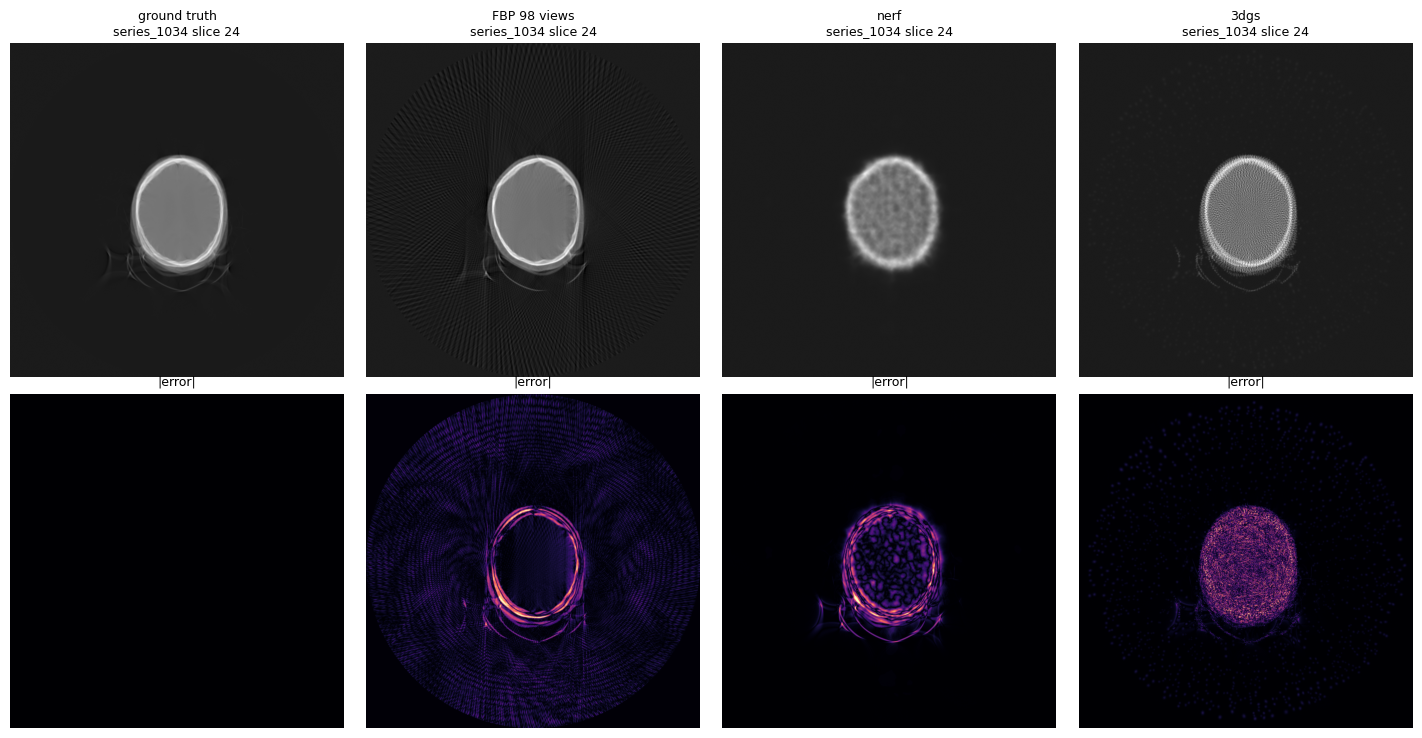

In [23]:
# If a method's images are flipped/rotated, set e.g. ORIENT["nerf"] = np.flipud  or  np.rot90
ORIENT = {m: (lambda x: x) for m in METHODS}

common = None
for m, fl in files.items():
    ids = {find_id(f) for f in fl if find_id(f)}
    common = ids if common is None else common & ids
common = sorted(i for i in (common or []) if i[0] in EVAL_SERIES and i[0] in SINO_FILES
                and (GT_ROOT / f"{i[0]}_slice{i[1]:02d}.npy").exists())
print(len(common), "slices are available for ALL methods and have a ground truth")
print("evaluated series:", sorted({s for s, _ in common}))

series, sl = common[len(common) // 2]
gt = minmax(load_gt(series, sl))
panels = {"ground truth": gt, f"FBP {N_VIEWS} views": match_intensity(as_png(fbp_baseline(series, sl)), gt)}
for m, fl in files.items():
    f = next(f for f in fl if find_id(f) == (series, sl))
    panels[m] = match_intensity(ORIENT[m](to_image(load_any(f), THETA_SPARSE)), gt)

fig, ax = plt.subplots(2, len(panels), figsize=(3.6 * len(panels), 7.4))
for j, (name, img) in enumerate(panels.items()):
    ax[0, j].imshow(img, cmap="gray", vmin=0, vmax=1); ax[0, j].set_title(f"{name}\n{series} slice {sl}", fontsize=9)
    ax[1, j].imshow(np.abs(img - gt), cmap="magma", vmin=0, vmax=0.3); ax[1, j].set_title("|error|", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(EVAL_DIR / "comparison_example.png", dpi=150); plt.show()

## 5. Metrics for all slices
Every method (and FBP) is scored on the **same slices**: those delivered by all methods.

In [24]:
rows = []
t0 = time.perf_counter()
for series, sl in common:
    gt = minmax(load_gt(series, sl))                          # ground truth scaled to 0-1
    preds = {"FBP": as_png(fbp_baseline(series, sl))}         # FBP with the same PNG treatment
    for m, fl in files.items():
        f = next(f for f in fl if find_id(f) == (series, sl))
        preds[m] = ORIENT[m](to_image(load_any(f), THETA_SPARSE))
    for name, pred in preds.items():
        pred = match_intensity(pred, gt)
        rows.append({"method": name, "series": series, "slice": sl, "views": N_VIEWS,
                     **metrics.evaluate(pred, gt, already_normalised=True)})
res = pd.DataFrame(rows)
res.to_csv(EVAL_DIR / "evaluation_all_slices.csv", index=False)
print(f"{len(common)} slices x {res.method.nunique()} methods in {time.perf_counter() - t0:.0f} s")

/tmp/ipykernel_1320/227842281.py:32: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(pred.ravel(), gt.ravel(), 1)
/tmp/ipykernel_1320/227842281.py:32: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(pred.ravel(), gt.ravel(), 1)
/tmp/ipykernel_1320/227842281.py:32: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(pred.ravel(), gt.ravel(), 1)
/tmp/ipykernel_1320/227842281.py:32: RankWarning: Polyfit may be poorly conditioned
  a, b = np.polyfit(pred.ravel(), gt.ravel(), 1)


92 slices x 3 methods in 342 s


## 6. Summary table and plot

In [25]:
cols = ["psnr", "ssim", "rmse", "psnr_head", "ssim_head", "rmse_head"]
summary = res.groupby("method")[cols].agg(["mean", "std"]).round(3)
summary.to_csv(EVAL_DIR / "evaluation_summary.csv")
summary

psnr          ssim          rmse        psnr_head        ssim_head  \
          mean    std   mean    std   mean    std      mean    std      mean   
method                                                                         
3dgs    33.256  4.151  0.933  0.024  0.024  0.008    22.413  3.470     0.367   
FBP     30.092  1.573  0.774  0.062  0.032  0.005    22.319  2.387     0.795   
nerf    32.110  1.523  0.958  0.010  0.025  0.004    22.549  1.814     0.679   

              rmse_head         
          std      mean    std  
method                          
3dgs    0.163     0.080  0.022  
FBP     0.089     0.081  0.038  
nerf    0.107     0.076  0.019

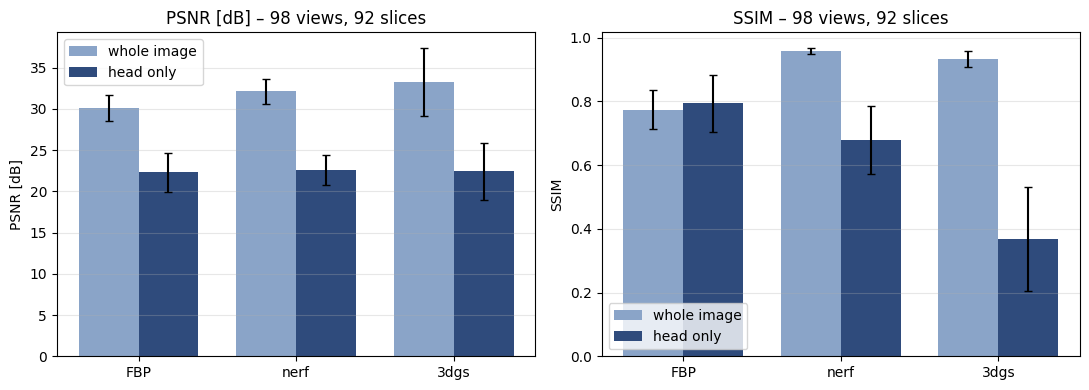

In [27]:
order = ["FBP"] + [m for m in files]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
w = 0.38
x = np.arange(len(order))
for a, metric, label in [(ax[0], "psnr", "PSNR [dB]"), (ax[1], "ssim", "SSIM")]:
    for k, (suffix, name, col) in enumerate([("", "whole image", "#8aa4c8"), ("_head", "head only", "#2f4b7c")]):
        g = res.groupby("method")[metric + suffix]
        a.bar(x + (k - 0.5) * w, g.mean()[order], w, yerr=g.std()[order], capsize=3, label=name, color=col)
    a.set_xticks(x); a.set_xticklabels(order); a.set_ylabel(label); a.grid(axis="y", alpha=0.3); a.legend()
    a.set_title(f"{label} – {N_VIEWS} views, {len(common)} slices")
plt.tight_layout(); plt.savefig(EVAL_DIR / "evaluation_bars.png", dpi=150); plt.show()

## Notes for the log / report
- Outputs were delivered as 8-bit PNGs → original intensity scale lost. All predictions
  (incl. FBP) are min-max scaled, rounded to 8 bit and then matched to the ground truth with a
  linear fit $a \cdot x + b$ (only brightness/contrast, not structure).
- Ground truth: full-view FBP (984 views, float) from `baseline_results/gt_fullview_npy`.
- All methods are scored on the same slices (validation series, slices delivered by all methods
  that have a ground truth = every 4th slice).

Results:
- PSNR is practically the same for all three methods (about $22.3$–$22.5$ dB). The differences are far smaller than the SD.
- SSIM: FBP $0.795$ > NeRF $0.679$ > 3DGS $0.367$.
- Equal PSNR combined with lower SSIM usually means the methods get the average grey values right but lose fine structure. NeRF blurs; 3DGS shows patchy or noisy texture. FBP has streaks but keeps edges and detail.

For the report: at 98 views (10%), NeRF and 3DGS remove the streak artefacts in the background, but they don’t reconstruct the head itself better than FBP. Our success criterion (“higher PSNR and SSIM than FBP”) is met for the whole image but not inside the head.

### FBP:

- Fine streaks in the whole background. That’s why its whole-image SSIM is lower.
- Inside the head the image looks closest to the ground truth: sharp skull, smooth brain.
- The error is concentrated in a thin ring along the skull edge, where the contrast is highest.

### NeRF:

- Very blurred. The skull is no longer a sharp ring but a soft edge, and the brain has a blotchy texture.
- The structures below the skull (neck, soft tissue) are missing almost entirely.
- The background is clean, which is why its whole-image SSIM is very high.
- Head-only, it’s clearly worse than FBP: typical underfitting / missing fine detail. The cause may be too few training iterations, too low a resolution or too weak positional encoding. Ask Samantha.

### 3DGS:

- The skull is reproduced well, but the brain is full of fine grainy texture. You can see the individual Gaussians.
- The background has scattered dots, so-called “floaters”.
- The ground-truth brain is very smooth, so this grain lowers the head SSIM a lot ($0.367$). It varies from slice to slice depending on how well the Gaussians converged, which explains the high SD.